# Graph features load

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    average_precision_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
    precision_recall_curve
)
import json
import logging
import platform
import sys
import time
import joblib



In [3]:

RESULTS_PATH = "../outputs/results/"

graph_df = pd.read_csv(
    RESULTS_PATH + "wallet_graph_features_with_labels.csv"
)

print(graph_df.shape)
graph_df.head()

(822942, 9)


,address,in_degree,out_degree,total_degree,degree_centrality,num_predecessors,num_successors,num_neighbors,class
0,13vHWR3iLsHeYwT42RnuKYNBoVPrKKZgRv,2198,1370,3568,0.004336,2198,1370,3553,2
1,1P9RQEr2XeE3PEb44ZE35sfZRRW1JHU8qx,3,1183,1186,0.001441,3,1183,1185,3
2,366Dgw4pi3rnvu5zizVWZF6nijWxZWc6RA,210,782,992,0.001205,210,782,991,3
3,1FoxBitjXcBeZUS4eDzPZ7b124q3N7QJK7,7,828,835,0.001015,7,828,834,2
4,33fjpQKTzzyQWu6T4PcXUxgbqRbd618u8U,1,575,576,0.000700,1,575,575,3


# Labeled data

In [4]:
labeled_df = graph_df[
    graph_df["class"].isin([1, 2])
].copy()

labeled_df["label"] = labeled_df["class"].map({
    1: 1,
    2: 0
})

print(labeled_df["label"].value_counts())

label
0    251088
1     14266
Name: count, dtype: int64


# Feature & target 

In [5]:
feature_cols = [
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_centrality",
    "num_predecessors",
    "num_successors",
    "num_neighbors"
]

X = labeled_df[feature_cols]
y = labeled_df["label"]

print("Features:", X.shape)
print("Labels:", y.shape)

Features: (265354, 7)
Labels: (265354,)


# Stratified split

In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Train class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation class distribution:")
print(y_val.value_counts(normalize=True) * 100)

print("\nTest class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Train class distribution:
label
0    94.62387
1     5.37613
Name: proportion, dtype: float64

Validation class distribution:
label
0    94.623521
1     5.376479
Name: proportion, dtype: float64

Test class distribution:
label
0    94.623656
1     5.376344
Name: proportion, dtype: float64


# Class-weighted Logistic Regression

In [7]:

log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Measure training time
start_time = time.perf_counter()
log_model.fit(X_train, y_train)
end_time = time.perf_counter()

training_time = end_time - start_time
print(f"Training time: {training_time:.4f} seconds")

y_val_prob = log_model.predict_proba(X_val)[:, 1]
y_test_prob = log_model.predict_proba(X_test)[:, 1]

print("Logistic Regression training complete.")

Training time: 0.2885 seconds
Logistic Regression training complete.


# Threshold tuning

In [8]:
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best threshold:", best_threshold)
print("Best validation F1:", f1_scores[best_index])


Best threshold: 0.5321365720279481
Best validation F1: 0.13761916399584279


# Evaluation

In [9]:
y_test_pred = (y_test_prob >= best_threshold).astype(int)

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Licit", "Illicit"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("PR-AUC:", average_precision_score(y_test, y_test_prob))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

              precision    recall  f1-score   support

       Licit       0.96      0.65      0.77     37664
     Illicit       0.08      0.53      0.14      2140

    accuracy                           0.64     39804
   macro avg       0.52      0.59      0.46     39804
weighted avg       0.91      0.64      0.74     39804

Confusion Matrix:
[[24392 13272]
 [ 1010  1130]]
PR-AUC: 0.062169903706318495
ROC-AUC: 0.5481750527537141


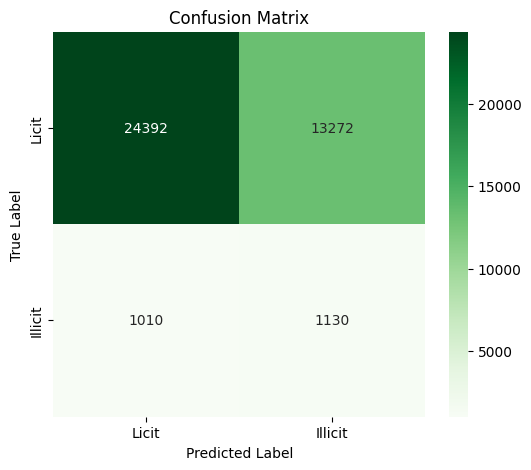

In [10]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=["Licit", "Illicit"], 
            yticklabels=["Licit", "Illicit"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

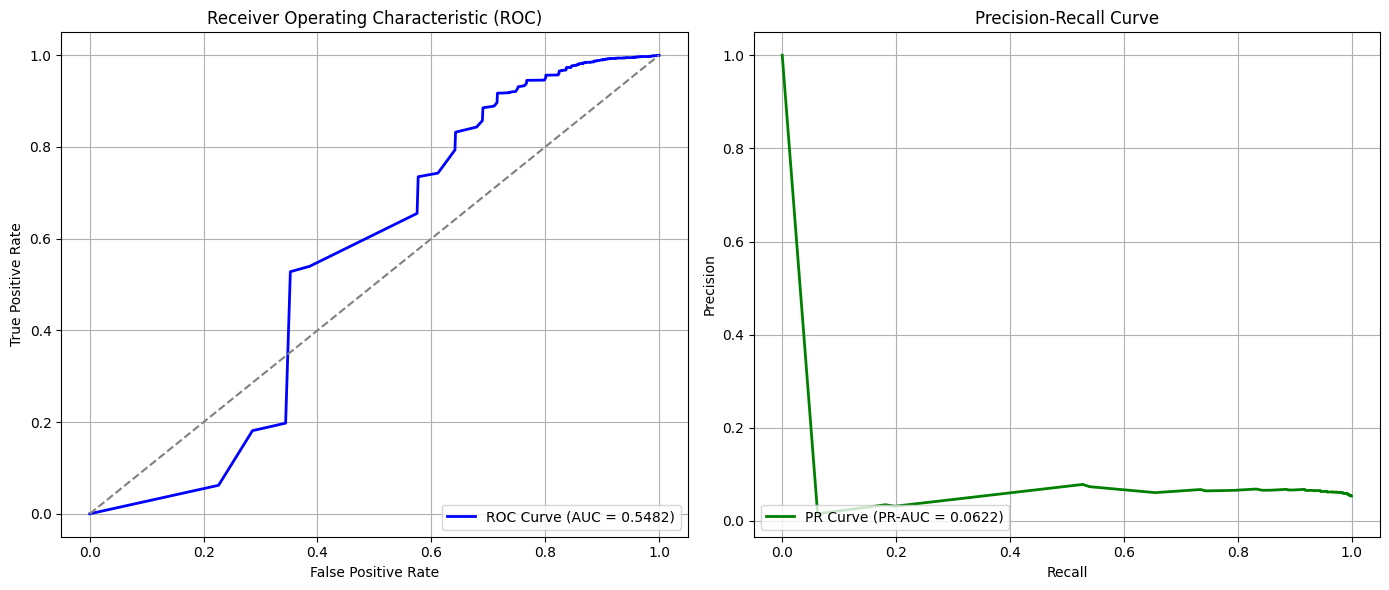

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_test_prob)
roc_auc = roc_auc_score(y_test, y_test_prob)
axes[0].plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_title('Receiver Operating Characteristic (ROC)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# Precision-Recall Curve (PR Curve)
precision, recall, _ = precision_recall_curve(y_test, y_test_prob)
pr_auc = average_precision_score(y_test, y_test_prob)
axes[1].plot(recall, precision, color='green', lw=2, label=f'PR Curve (PR-AUC = {pr_auc:.4f})')
axes[1].set_title('Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# XGBoost model

In [12]:
# 1. Compute sample weights for class imbalance
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# 2. Initialize XGBoost model
xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

# 3. Fit model and measure training time
start_time = time.perf_counter()
xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)
end_time = time.perf_counter()
print(f"XGBoost Training Time: {end_time - start_time:.4f} seconds\n")


XGBoost Training Time: 4.4410 seconds



In [13]:
# 4. Get validation probabilities and perform Vectorized Threshold Tuning
y_val_prob = xgb_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_val, y_val_prob)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print(f"Optimal Threshold (based on Validation F1): {best_threshold:.4f}")
print(f"Best validation F1: {f1_scores[best_index]:.4f}\n")

Optimal Threshold (based on Validation F1): 0.9241
Best validation F1: 0.5834



In [14]:
# 5. Validation Evaluation
y_val_pred = (y_val_prob >= best_threshold).astype(int)
print("--- Validation Set Evaluation ---")
print(classification_report(y_val, y_val_pred))
print(f"Validation ROC-AUC: {roc_auc_score(y_val, y_val_prob):.4f}\n")


--- Validation Set Evaluation ---
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     37663
           1       0.69      0.51      0.58      2140

    accuracy                           0.96     39803
   macro avg       0.83      0.75      0.78     39803
weighted avg       0.96      0.96      0.96     39803

Validation ROC-AUC: 0.8752



In [15]:

# 6. Test Evaluation
xgb_test_prob = xgb_model.predict_proba(X_test)[:, 1]
xgb_test_pred = (xgb_test_prob >= best_threshold).astype(int)
print("--- Test Set Evaluation ---")
print(classification_report(y_test, xgb_test_pred))
print(f"Test ROC-AUC: {roc_auc_score(y_test, xgb_test_prob):.4f}")

--- Test Set Evaluation ---
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     37664
           1       0.67      0.52      0.58      2140

    accuracy                           0.96     39804
   macro avg       0.82      0.75      0.78     39804
weighted avg       0.96      0.96      0.96     39804

Test ROC-AUC: 0.8778


In [16]:
print(classification_report(
    y_test,
    xgb_test_pred,
    target_names=["Licit", "Illicit"]
))

              precision    recall  f1-score   support

       Licit       0.97      0.99      0.98     37664
     Illicit       0.67      0.52      0.58      2140

    accuracy                           0.96     39804
   macro avg       0.82      0.75      0.78     39804
weighted avg       0.96      0.96      0.96     39804



In [17]:
xgb_roc_auc = roc_auc_score(y_test, xgb_test_prob)
xgb_pr_auc = average_precision_score(y_test, xgb_test_prob)

print(f"XGBoost ROC-AUC : {xgb_roc_auc:.4f}")
print(f"XGBoost PR-AUC  : {xgb_pr_auc:.4f}")


XGBoost ROC-AUC : 0.8778
XGBoost PR-AUC  : 0.4622


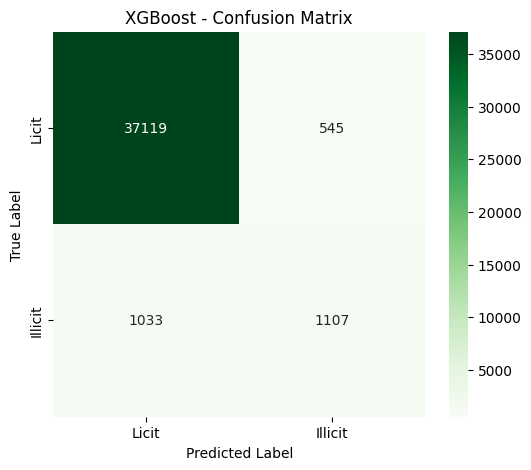

In [18]:

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, xgb_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=["Licit", "Illicit"], 
            yticklabels=["Licit", "Illicit"])
plt.title("XGBoost - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

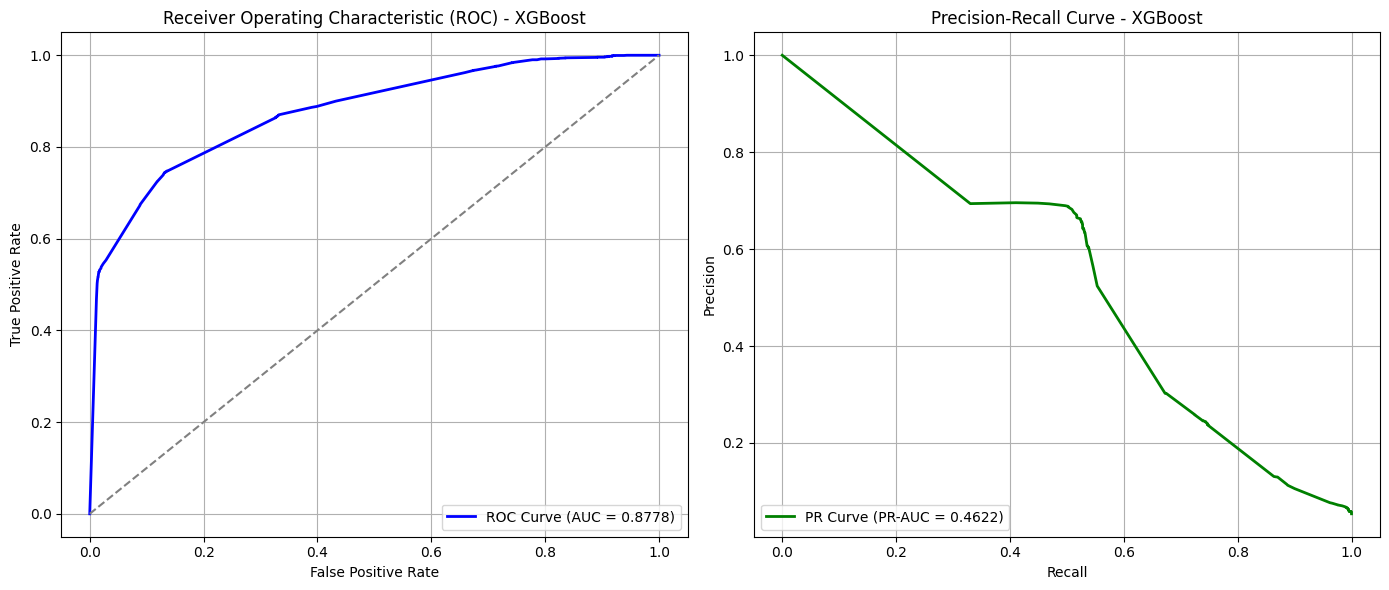

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ROC Curve for XGBoost
fpr, tpr, _ = roc_curve(y_test, xgb_test_prob)
roc_auc = roc_auc_score(y_test, xgb_test_prob)
axes[0].plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_title('Receiver Operating Characteristic (ROC) - XGBoost')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# Precision-Recall Curve (PR Curve) for XGBoost
precision, recall, _ = precision_recall_curve(y_test, xgb_test_prob)
pr_auc = average_precision_score(y_test, xgb_test_prob)
axes[1].plot(recall, precision, color='green', lw=2, label=f'PR Curve (PR-AUC = {pr_auc:.4f})')
axes[1].set_title('Precision-Recall Curve - XGBoost')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Random Forest

In [20]:
# 1. Compute sample weights for class imbalance
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# 2. Initialize Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# 3. Fit model and measure training time
start_time = time.perf_counter()
rf_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)
end_time = time.perf_counter()
print(f"Random Forest Training Time: {end_time - start_time:.4f} seconds\n")

Random Forest Training Time: 23.0591 seconds



# Threshold Tuning

In [21]:
# 4. Get validation probabilities and perform Vectorized Threshold Tuning
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_val, y_val_prob_rf)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

best_index = np.argmax(f1_scores)
best_threshold_rf = thresholds[best_index]

print(f"Optimal Threshold (based on Validation F1): {best_threshold_rf:.4f}")
print(f"Best validation F1: {f1_scores[best_index]:.4f}\n")

Optimal Threshold (based on Validation F1): 0.9961
Best validation F1: 0.5832



# Evaluation

In [22]:
# 5. Validation Evaluation
y_val_pred_rf = (y_val_prob_rf >= best_threshold_rf).astype(int)
print("--- Validation Set Evaluation ---")
print(classification_report(y_val, y_val_pred_rf, target_names=["Licit", "Illicit"]))
print(f"Validation ROC-AUC: {roc_auc_score(y_val, y_val_prob_rf):.4f}\n")

--- Validation Set Evaluation ---
              precision    recall  f1-score   support

       Licit       0.97      0.99      0.98     37663
     Illicit       0.69      0.50      0.58      2140

    accuracy                           0.96     39803
   macro avg       0.83      0.75      0.78     39803
weighted avg       0.96      0.96      0.96     39803

Validation ROC-AUC: 0.8707



In [23]:
# 6. Test Evaluation
rf_test_prob = rf_model.predict_proba(X_test)[:, 1]
rf_test_pred = (rf_test_prob >= best_threshold_rf).astype(int)

print("--- Test Set Evaluation ---")
print(classification_report(
    y_test,
    rf_test_pred,
    target_names=["Licit", "Illicit"]
))

rf_roc_auc = roc_auc_score(y_test, rf_test_prob)
rf_pr_auc = average_precision_score(y_test, rf_test_prob)

print(f"Random Forest ROC-AUC : {rf_roc_auc:.4f}")
print(f"Random Forest PR-AUC  : {rf_pr_auc:.4f}")

--- Test Set Evaluation ---
              precision    recall  f1-score   support

       Licit       0.97      0.99      0.98     37664
     Illicit       0.68      0.51      0.58      2140

    accuracy                           0.96     39804
   macro avg       0.83      0.75      0.78     39804
weighted avg       0.96      0.96      0.96     39804

Random Forest ROC-AUC : 0.8713
Random Forest PR-AUC  : 0.4580


#  Confusion Matrix Plot

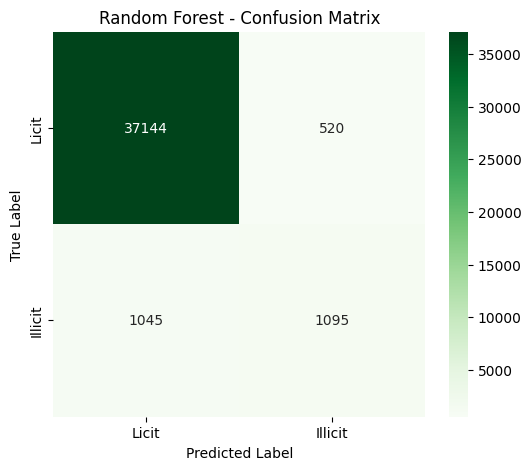

In [24]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, rf_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=["Licit", "Illicit"], 
            yticklabels=["Licit", "Illicit"])
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

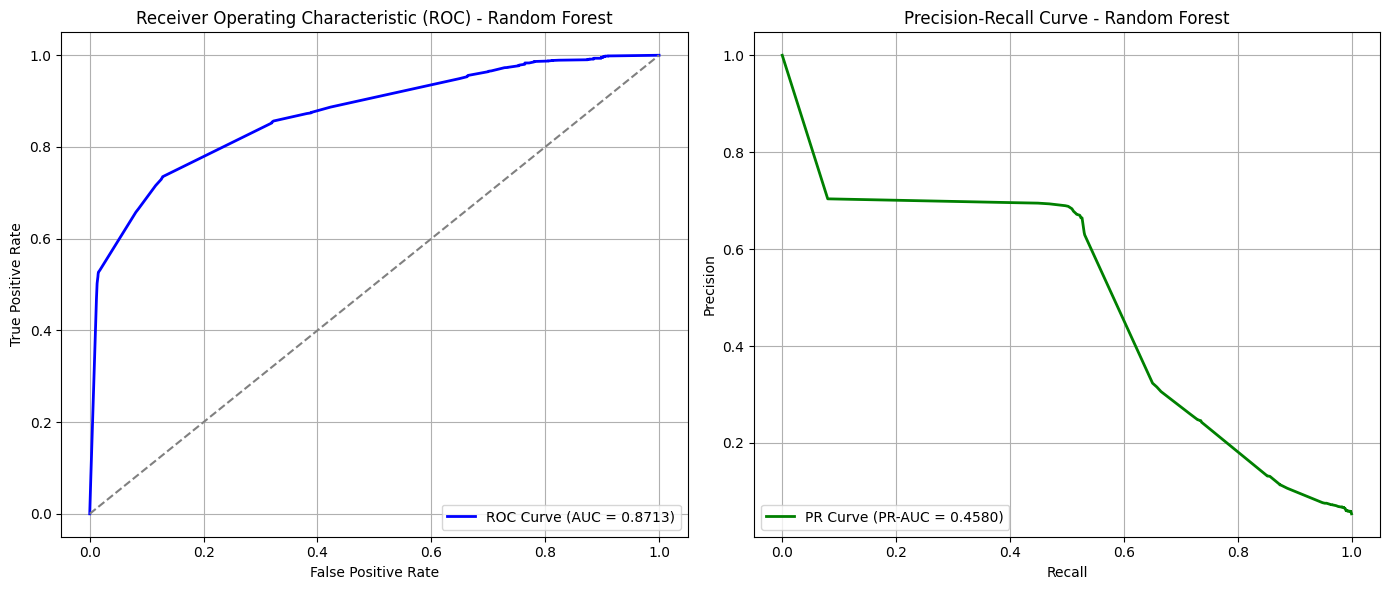

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. ROC Curve for Random Forest
fpr, tpr, _ = roc_curve(y_test, rf_test_prob)
roc_auc = roc_auc_score(y_test, rf_test_prob)
axes[0].plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_title('Receiver Operating Characteristic (ROC) - Random Forest')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# 2. Precision-Recall Curve (PR Curve) for Random Forest
precision, recall, _ = precision_recall_curve(y_test, rf_test_prob)
pr_auc = average_precision_score(y_test, rf_test_prob)
axes[1].plot(recall, precision, color='green', lw=2, label=f'PR Curve (PR-AUC = {pr_auc:.4f})')
axes[1].set_title('Precision-Recall Curve - Random Forest')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# comparison

In [27]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

models = {
    "Logistic Regression": (y_test_pred, y_test_prob),
    "Random Forest": (rf_test_pred, rf_test_prob),
    "XGBoost": (xgb_test_pred, xgb_test_prob)
}

results = []

for name, (pred, prob) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Illicit Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Illicit Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "Illicit F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="PR-AUC", ascending=False
).reset_index(drop=True)

print(comparison_df.round(4).to_string(index=False))


              Model  Accuracy  Illicit Precision  Illicit Recall  Illicit F1  ROC-AUC  PR-AUC
            XGBoost    0.9604             0.6701          0.5173      0.5839   0.8778  0.4622
      Random Forest    0.9607             0.6780          0.5117      0.5832   0.8713  0.4580
Logistic Regression    0.6412             0.0785          0.5280      0.1366   0.5482  0.0622


# Visualize the comparison

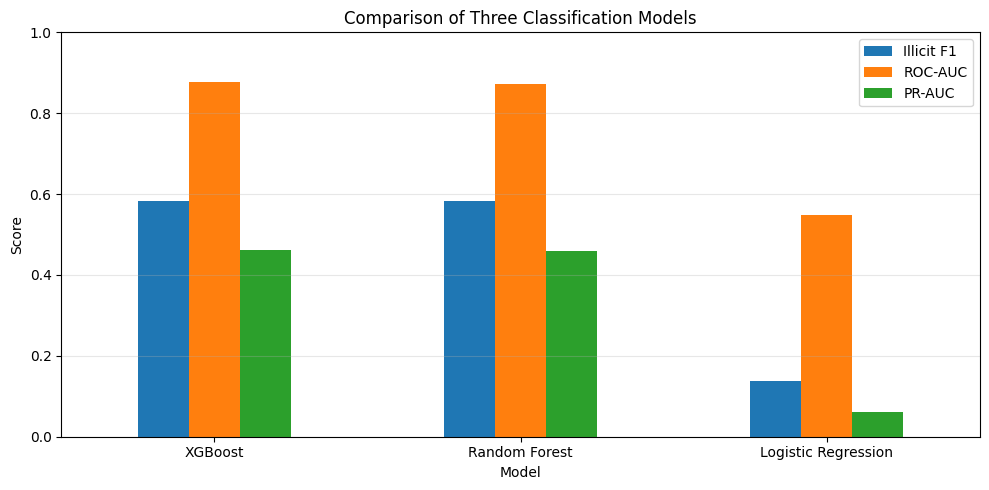

In [29]:

metrics = ["Illicit F1", "ROC-AUC", "PR-AUC"]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparison of Three Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="upper right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:
comparison_df.to_csv(
    "../outputs/results/model_comparison.csv",
    index=False
)

In [33]:

import joblib
from pathlib import Path

# Create model directory
MODEL_DIR = Path("../outputs/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save trained XGBoost model
xgb_model.save_model(
    str(MODEL_DIR / "xgboost_fraud_model.json")
)

# 2. Save best classification threshold
joblib.dump(
    best_threshold,
    MODEL_DIR / "xgboost_best_threshold.pkl"
)

# 3. Save feature column names and order
joblib.dump(
    feature_cols,
    MODEL_DIR / "feature_columns.pkl"
)

print("Model, threshold, and feature columns saved successfully!")

print("Saved files:")
for file in MODEL_DIR.iterdir():
    print(file)


Model, threshold, and feature columns saved successfully!
Saved files:
..\outputs\models\feature_columns.pkl
..\outputs\models\xgboost_best_threshold.pkl
..\outputs\models\xgboost_fraud_model.json


In [34]:

import joblib
import xgboost as xgb
from pathlib import Path

MODEL_DIR = Path("../outputs/models")

# Load model
loaded_model = xgb.XGBClassifier()
loaded_model.load_model(
    str(MODEL_DIR / "xgboost_fraud_model.json")
)

# Load threshold and feature columns
loaded_threshold = joblib.load(
    MODEL_DIR / "xgboost_best_threshold.pkl"
)

loaded_features = joblib.load(
    MODEL_DIR / "feature_columns.pkl"
)

print("Model loaded successfully!")
print("Threshold:", loaded_threshold)
print("Number of features:", len(loaded_features))


Model loaded successfully!
Threshold: 0.92411923
Number of features: 7
